# 09 Country clustering: which African countries share an environmental profile?

**Method**
1. **Features:** country averages over 2015 to 2022 for 12 measures across the six dimensions. Averaging smooths single-year noise.
2. **Transform:** skewed level measures are logged, then everything is robust-scaled and standardised.
3. **Reduce:** principal component analysis keeps 85% of the variance.
4. **Cluster:** k-means, with the number of clusters chosen by silhouette over k = 2 to 8. Ward hierarchical clustering is run as a cross-check.
5. **Validate:**
   - Silhouette score.
   - Agreement between the two methods (adjusted Rand index).
   - Bootstrap stability: the mean Jaccard overlap of each cluster across 200 resamples. Above 0.75 is stable; below 0.5 means the cluster is not reliable.

Clusters are described by their profiles. Names are given only after looking at the profiles, not assumed in advance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "09 clustering"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

In [2]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import RobustScaler, StandardScaler

## 1. Feature matrix

In [3]:
FEATURES = ["A01", "X01", "B10E", "B06", "B08", "C01", "X02", "D11", "E08", "F02", "F03", "G02"]
LOG = {"A01", "X01", "G02", "X02"}
win = afp[afp["year"].between(2015, 2022)]
avg = win.groupby("iso3")[[f for f in FEATURES if f in win]].mean()
keep = [c for c in avg if avg[c].isna().mean() <= 0.3]
dropped_feats = sorted(set(avg.columns) - set(keep))
X = avg[keep].dropna()
dropped_countries = sorted(set(AFRICA) - set(X.index))
print(f"{len(X)} countries x {len(keep)} features. Features dropped (over 30% missing): {dropped_feats or 'none'}")
print(f"Countries excluded for incomplete data: {', '.join(name.get(c, c) for c in dropped_countries) or 'none'}")
Xt = X.copy()
for c in keep:
    if c in LOG:
        Xt[c] = np.log1p(Xt[c].clip(lower=0))
Z = StandardScaler().fit_transform(RobustScaler().fit_transform(Xt))

52 countries x 12 features. Features dropped (over 30% missing): none
Countries excluded for incomplete data: Eritrea, South Sudan


**52 countries with complete data across 12 features.** Eritrea and South Sudan are excluded for missing data.

## 2. Principal components

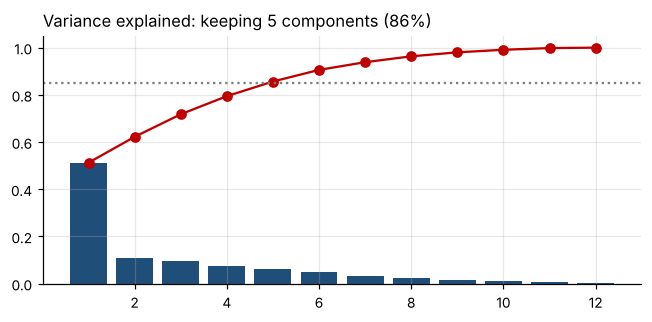

,PC1,PC2,PC3
A01,0.370,0.030,-0.260
X01,0.290,-0.160,-0.360
B10E,-0.200,0.410,-0.090
B06,0.360,0.070,0.130
B08,0.360,-0.020,-0.120
C01,-0.050,0.550,-0.470
X02,-0.110,0.470,0.340
D11,0.360,-0.090,0.100
E08,-0.190,-0.310,-0.430
F02,-0.300,-0.390,0.020


In [4]:
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
n_comp = int(np.searchsorted(cum, 0.85) + 1)
P = PCA(n_components=n_comp).fit_transform(Z)
loadings = pd.DataFrame(pca.components_[:3].T, index=keep, columns=["PC1", "PC2", "PC3"]).round(2)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color=BLUE); ax.plot(range(1, len(cum) + 1), cum, "o-", color=RED)
ax.axhline(0.85, color=GREY, ls=":"); ax.set_title(f"Variance explained: keeping {n_comp} components ({cum[n_comp-1]:.0%})", loc="left")
fig.tight_layout(); fig.savefig(OUT / "pca scree.png", dpi=150); plt.show()
loadings

**One development axis dominates:** PC1 explains 51.3% of the variance and loads on income, emissions, electricity access, clean cooking, drinking water and readiness. Five components keep 85.7%.

## 3. How many clusters?

In [5]:
sil = {k: silhouette_score(P, KMeans(k, n_init=50, random_state=11).fit_predict(P)) for k in range(2, min(9, len(X)))}
k = max(sil, key=sil.get)
km = KMeans(k, n_init=50, random_state=11).fit_predict(P)
ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(P)
print(f"Chosen k = {k} (silhouette {sil[k]:.3f}); agreement with Ward clustering, adjusted Rand = {adjusted_rand_score(km, ward):.3f}")
pd.Series(sil, name="silhouette").to_frame().T

Chosen k = 2 (silhouette 0.437); agreement with Ward clustering, adjusted Rand = 1.000


,2,3,4,5,6,7,8
silhouette,0.437,0.221,0.232,0.243,0.255,0.282,0.303


**The data splits most cleanly into two groups (silhouette 0.437, against 0.30 or less for 3 to 8 groups), and Ward clustering agrees exactly (adjusted Rand 1.000).**

## 4. Are the clusters stable? (bootstrap)

In [6]:
rng = np.random.default_rng(11)
base = {c: set(X.index[km == c]) for c in range(k)}
stab = {c: [] for c in range(k)}
for _ in range(200):
    idx = np.unique(rng.choice(len(X), len(X), replace=True))
    lab = KMeans(k, n_init=10, random_state=int(rng.integers(1e9))).fit_predict(P[idx])
    boots = [set(X.index[idx][lab == j]) for j in range(k)]
    for c, s in base.items():
        s_in = s & set(X.index[idx])
        if s_in:
            stab[c].append(max(len(s_in & b) / len(s_in | b) for b in boots))
stability = pd.Series({c: np.mean(v) for c, v in stab.items()}, name="mean Jaccard")
stability

0   0.993
1   0.980
Name: mean Jaccard, dtype: float64

**Both clusters are highly stable:** mean bootstrap Jaccard 0.993 and 0.980.

## 5. Cluster profiles

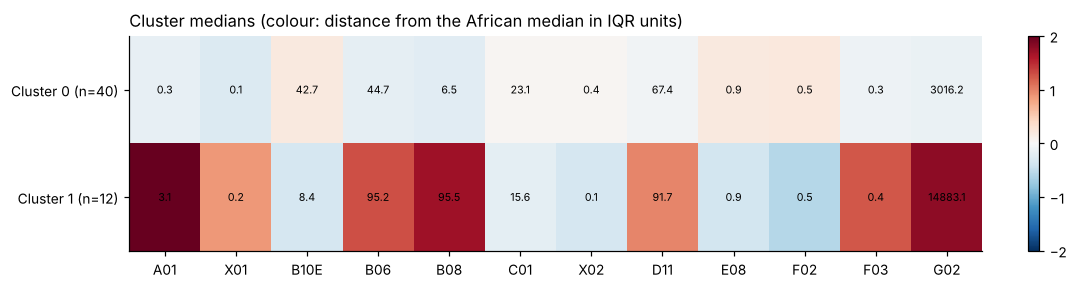

,countries,stability,highest,lowest,members
0,40,0.993,"F02, E08, B10E","X01, B08, B06","Angola, Burundi, Benin, Burkina Faso, Central ..."
1,12,0.980,"A01, G02, B08","F02, E08, B10E","Botswana, Cabo Verde, Algeria, Egypt, Gabon, E..."


In [7]:
prof = X.assign(cluster=km).groupby("cluster").median()
z = (prof - X.median()) / (X.quantile(0.75) - X.quantile(0.25)).replace(0, np.nan)
fig, ax = plt.subplots(figsize=(10, 0.6 * k + 1.5))
im = ax.imshow(z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(keep)), keep); ax.set_yticks(range(k), [f"Cluster {c} (n={int((km == c).sum())})" for c in range(k)]); ax.grid(False)
for i in range(k):
    for j in range(len(keep)):
        ax.text(j, i, f"{prof.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Cluster medians (colour: distance from the African median in IQR units)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.02); fig.tight_layout(); fig.savefig(OUT / "cluster profiles.png", dpi=150); plt.show()

desc = pd.DataFrame({"countries": [int((km == c).sum()) for c in range(k)], "stability": stability.values,
                     "highest": [", ".join(z.loc[c].sort_values(ascending=False).index[:3]) for c in range(k)],
                     "lowest": [", ".join(z.loc[c].sort_values().index[:3]) for c in range(k)],
                     "members": [", ".join(name.get(i, i) for i in X.index[km == c]) for c in range(k)]})
desc

**The two groups are a development divide, not separate environmental types.**

- **Cluster 1 (12 countries):** higher income and emissions, broad energy access, lower vulnerability and a lower Red List Index (more threatened species, mainly in the island states). Members: Botswana, Cabo Verde, Algeria, Egypt, Gabon, Equatorial Guinea, Libya, Morocco, Mauritius, Seychelles, Tunisia and South Africa.
- **Cluster 0 (40 countries):** lower income and emissions, higher renewable electricity shares, low clean cooking access, higher vulnerability and a higher Red List Index.

## 6. Map and save

In [8]:
import plotly.express as px

assign = pd.DataFrame({"iso3": X.index, "cluster": km, "cluster_ward": ward})
assign.to_csv(DATA / "clusters.csv", index=False)
fig = px.choropleth(assign.assign(cluster=assign["cluster"].astype(str), country=assign["iso3"].map(name)), locations="iso3",
                    color="cluster", hover_name="country", scope="africa", title="Country clusters")
fig.write_html(OUT / "cluster map.html"); fig.show()
save_excel("clustering results.xlsx", {"Clusters": desc, "Profiles median": prof, "Assignments": assign.set_index("iso3"),
                                       "Silhouette": pd.Series(sil, name="silhouette").to_frame(), "PCA loadings": loadings})

['cluster map.html',
 'cluster profiles.png',
 'clustering results.xlsx',
 'pca scree.png']

## What I found

- **Africa's environmental profile is mainly a development story:** one axis explains half the variation, and the cleanest split is 12 higher-income, higher-emission, lower-vulnerability countries against 40 others.
- **The split is very stable** (Jaccard 0.98 or higher, and two methods agree exactly).
- **The brief's five groups are not supported by the data at this level.** Finer groupings (k = 3 to 8) have weak silhouettes. Within the 40-country group, the dimension notebooks give more useful distinctions (hydro dependence, deforestation, water stress) than a clustering does.

**Why it matters for finance:** for portfolio screening, a two-tier view (North Africa, South Africa and the islands against the rest) captures most of the cross-country environmental variation. Dimension-specific risk (deforestation, water, hydro) still has to be assessed country by country.